# Regression Track — Used Car Price Prediction
23CSE301 ML Capstone

Predicting the listed **price** of a used car from its attributes, using the [Used Cars dataset](https://www.kaggle.com/datasets/thedevastator/uncovering-factors-that-affect-used-car-prices) (`data/raw/autos.csv`).

All 10 required regression algorithms are trained on the same preprocessed dataset and evaluated on the same held-out test set.

## Section A — Dataset & EDA

### A1. Dataset Loading & Audit

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="colorblind")

df = pd.read_csv("../data/raw/autos.csv", encoding="latin-1")
print("Shape:", df.shape)
df.info()

Shape: (371528, 21)
<class 'pandas.DataFrame'>
RangeIndex: 371528 entries, 0 to 371527
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   index                371528 non-null  int64
 1   dateCrawled          371528 non-null  str  
 2   name                 371528 non-null  str  
 3   seller               371528 non-null  str  
 4   offerType            371528 non-null  str  
 5   price                371528 non-null  int64
 6   abtest               371528 non-null  str  
 7   vehicleType          333659 non-null  str  
 8   yearOfRegistration   371528 non-null  int64
 9   gearbox              351319 non-null  str  
 10  powerPS              371528 non-null  int64
 11  model                351044 non-null  str  
 12  kilometer            371528 non-null  int64
 13  monthOfRegistration  371528 non-null  int64
 14  fuelType             338142 non-null  str  
 15  brand                371528 non-null  str 

In [2]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False))
print("\nTarget (price) distribution:")
print(df["price"].describe())

Missing values per column:


notRepairedDamage      72060
vehicleType            37869
fuelType               33386
model                  20484
gearbox                20209
offerType                  0
seller                     0
name                       0
dateCrawled                0
index                      0
abtest                     0
yearOfRegistration         0
price                      0
kilometer                  0
powerPS                    0
monthOfRegistration        0
brand                      0
dateCreated                0
nrOfPictures               0
postalCode                 0
lastSeen                   0
dtype: int64

Target (price) distribution:
count    3.715280e+05
mean     1.729514e+04
std      3.587954e+06
min      0.000000e+00
25%      1.150000e+03
50%      2.950000e+03
75%      7.200000e+03
max      2.147484e+09
Name: price, dtype: float64


**Observation:** the raw dataset has ~371k listings and 21 columns. `vehicleType`, `gearbox`, `model`, `fuelType`, and `notRepairedDamage` all have substantial missingness (5k–38k rows). The raw `price` column has extreme outliers (max > 2 billion) that are clearly data-entry errors and must be filtered before modelling.

### A2. EDA Visualisations

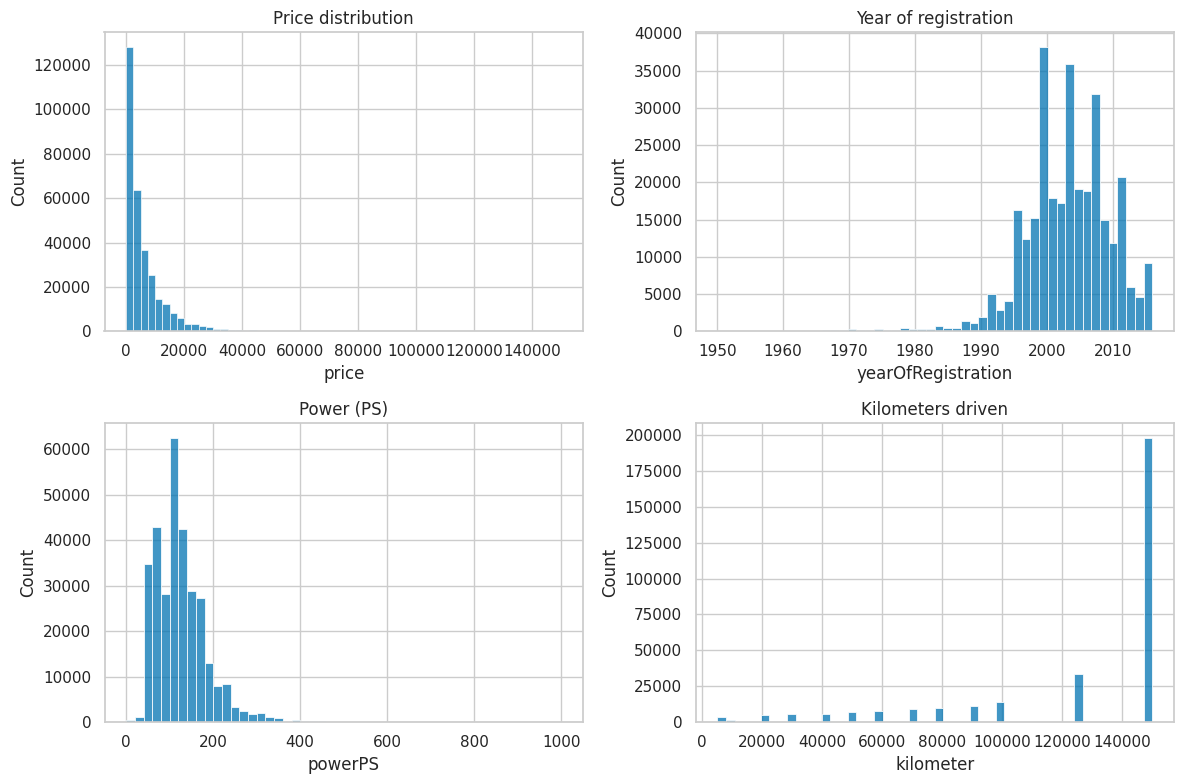

In [3]:
# Work on a realistic price/year range for the EDA plots (full cleaning happens in Section B)
df_eda = df[(df["price"] >= 100) & (df["price"] <= 150000)]
df_eda = df_eda[(df_eda["yearOfRegistration"] >= 1950) & (df_eda["yearOfRegistration"] <= 2016)]
df_eda = df_eda[(df_eda["powerPS"] > 0) & (df_eda["powerPS"] <= 1000)]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df_eda["price"], bins=60, ax=axes[0, 0]).set_title("Price distribution")
sns.histplot(df_eda["yearOfRegistration"], bins=50, ax=axes[0, 1]).set_title("Year of registration")
sns.histplot(df_eda["powerPS"], bins=50, ax=axes[1, 0]).set_title("Power (PS)")
sns.histplot(df_eda["kilometer"], bins=50, ax=axes[1, 1]).set_title("Kilometers driven")
plt.tight_layout()
plt.show()

**Insight:** `price` is heavily right-skewed — most cars sell under €10,000 with a long tail of premium vehicles. `yearOfRegistration` peaks around 2000–2008. `powerPS` and `kilometer` are both right-skewed, with a large spike at 150,000 km (the odometer's max bucket in this dataset).

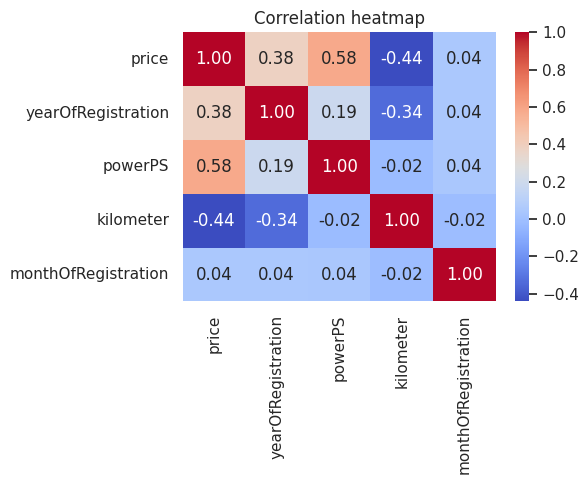

In [4]:
numeric_cols = ["price", "yearOfRegistration", "powerPS", "kilometer", "monthOfRegistration"]
plt.figure(figsize=(6, 5))
sns.heatmap(df_eda[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

**Insight:** `yearOfRegistration` has the strongest positive correlation with `price` (newer cars cost more), while `kilometer` correlates negatively as expected. `powerPS` also correlates positively with price. None of the numeric features are strongly correlated with each other, so multicollinearity among numeric features is not a major concern.

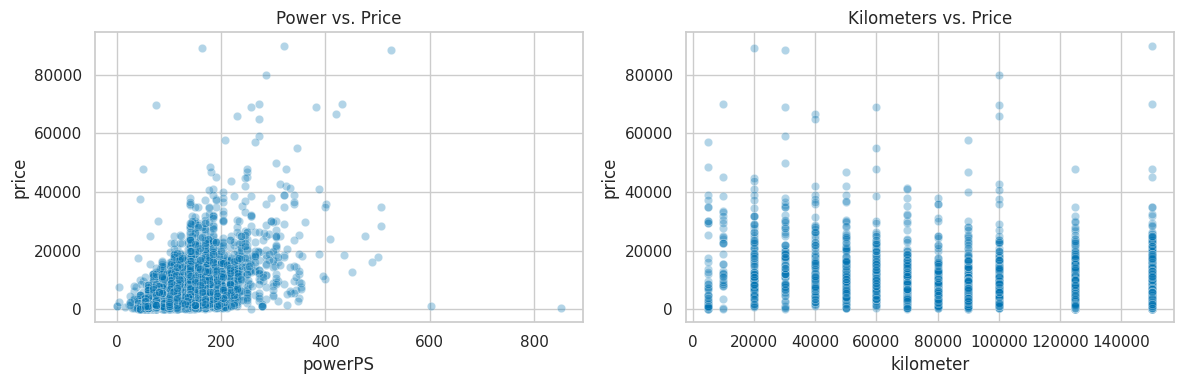

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df_eda.sample(5000, random_state=RANDOM_STATE), x="powerPS", y="price", alpha=0.3, ax=axes[0]).set_title("Power vs. Price")
sns.scatterplot(data=df_eda.sample(5000, random_state=RANDOM_STATE), x="kilometer", y="price", alpha=0.3, ax=axes[1]).set_title("Kilometers vs. Price")
plt.tight_layout()
plt.show()

**Insight:** price rises with engine power, roughly linearly for most of the range with a steeper climb for high-power (sports/luxury) cars. Price falls as mileage increases, most sharply in the first 50,000–100,000 km, consistent with typical vehicle depreciation curves.

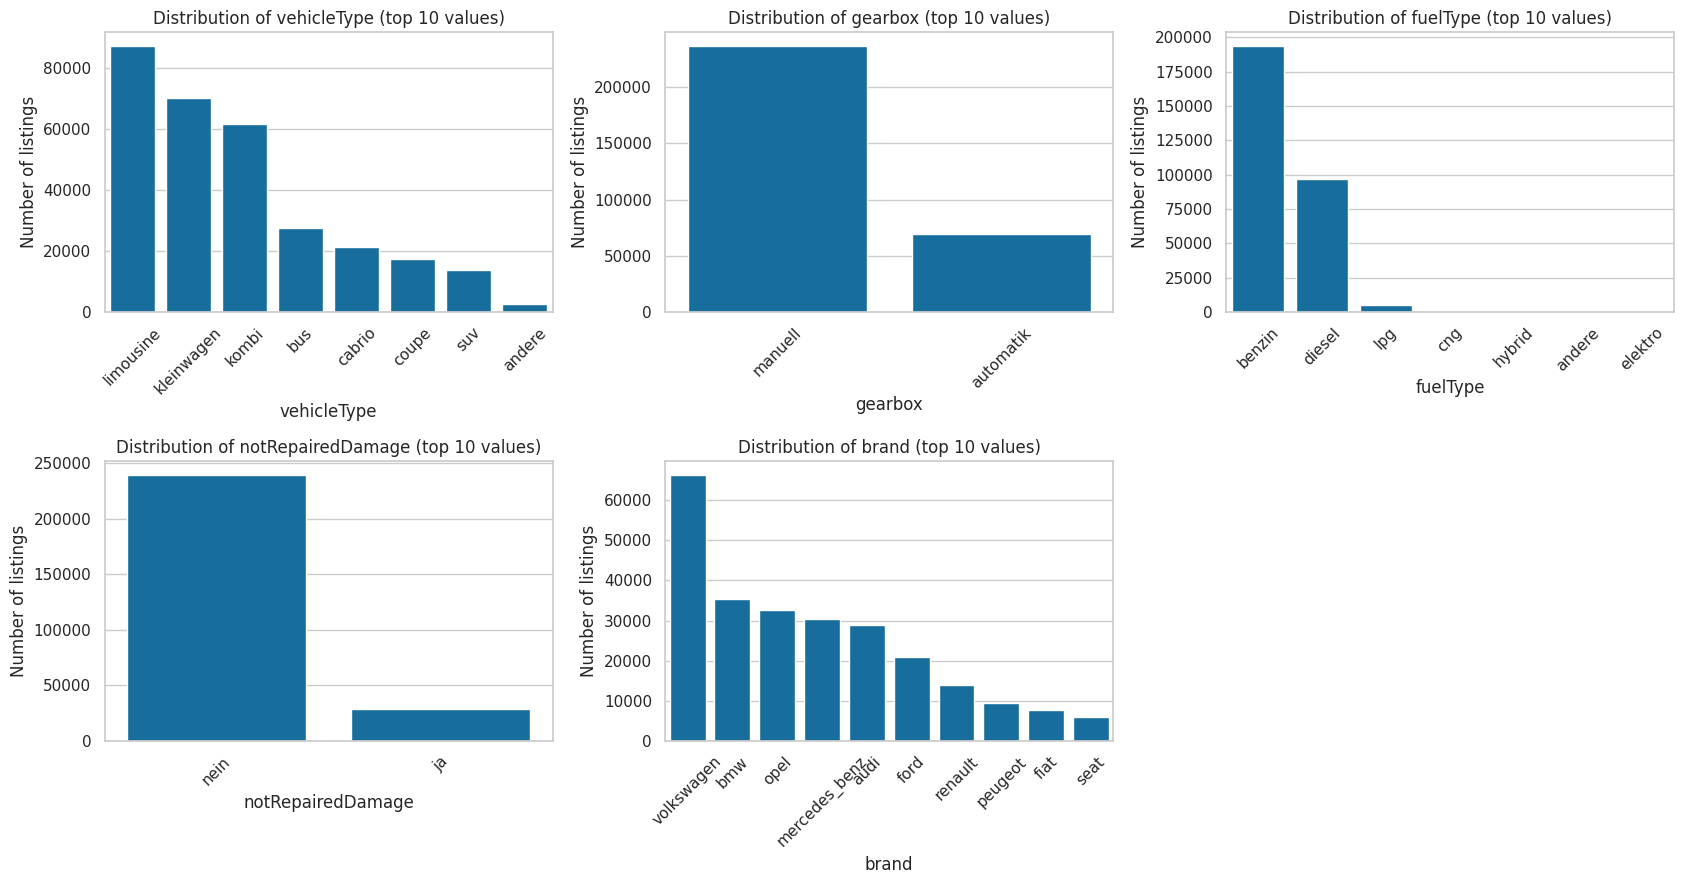

In [ ]:
# Distribution plots for the categorical features (A2: "distribution plots for each feature")
cat_cols_eda = ["vehicleType", "gearbox", "fuelType", "notRepairedDamage", "brand"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    order = df_eda[col].value_counts().head(10).index
    sns.countplot(data=df_eda, x=col, order=order, ax=ax)
    ax.set_title(f"Distribution of {col} (top 10 values)")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of listings")
    ax.tick_params(axis="x", rotation=45)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Observation:** the categorical features are dominated by a few mainstream values. `vehicleType` is led by *limousine* (~87k listings), *kleinwagen* (~70k) and *kombi* (~62k); the rest (bus, cabrio, coupe, suv) are far smaller. `gearbox` is roughly 77 % manual / 23 % automatic, and `fuelType` is almost entirely *benzin* (~193k) and *diesel* (~97k) — LPG, CNG, hybrid and electric together are a negligible sliver. About 90 % of listings with a known `notRepairedDamage` value are *nein* (no unrepaired damage). `brand` is led by Volkswagen (~66k), followed by BMW, Opel, Mercedes-Benz and Audi — a typical German used-car market. Two consequences for modelling: (1) rare levels (hybrid/electric, `andere`, niche brands and models) give the models very few examples to learn from, so their one-hot columns are noisy; (2) the class imbalance inside `notRepairedDamage` and `gearbox` means those features describe a minority of cars and are unlikely to be the main price drivers on their own.

## Section B — Preprocessing & Feature Engineering

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# --- B1. Cleaning (documented, justified filtering) ---
df_clean = df[(df["price"] >= 100) & (df["price"] <= 150000)]
df_clean = df_clean[(df_clean["yearOfRegistration"] >= 1950) & (df_clean["yearOfRegistration"] <= 2016)]
df_clean = df_clean[(df_clean["powerPS"] > 0) & (df_clean["powerPS"] <= 1000)]
df_clean = df_clean.drop_duplicates(subset=[c for c in df_clean.columns if c != "index"])

drop_cols = ["index", "dateCrawled", "name", "nrOfPictures", "postalCode", "dateCreated", "lastSeen", "offerType", "abtest", "seller"]
df_clean = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

# --- B3. Feature engineering: vehicle age is more informative than raw registration year ---
df_clean["vehicle_age"] = 2016 - df_clean["yearOfRegistration"]  # dataset was crawled in 2016
df_clean = df_clean.reset_index(drop=True)

print("Cleaned shape:", df_clean.shape)

# Subsample for computational feasibility (SVR / GridSearchCV do not scale well on limited hardware)
df_model = df_clean.sample(n=8000, random_state=RANDOM_STATE).reset_index(drop=True)

numeric_features = ["vehicle_age", "powerPS", "kilometer", "monthOfRegistration"]
categorical_features = ["vehicleType", "gearbox", "model", "fuelType", "brand", "notRepairedDamage"]

X = df_model[numeric_features + categorical_features]
y = df_model["price"]

# --- B2. Split first, then fit scalers/encoders on train only (avoid leakage) ---
price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_bins
)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Numeric-only polynomial expansion (used only by the Polynomial Regression model —
# expanding one-hot columns polynomially would blow up dimensionality without adding signal)
poly_preprocessor = ColumnTransformer([
    ("num_poly", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("poly", PolynomialFeatures(degree=2, include_bias=False))]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
X_train_poly = poly_preprocessor.fit_transform(X_train)
X_test_poly = poly_preprocessor.transform(X_test)

# SVR is sensitive to target scale; a separately-scaled target is available for that model
target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

print("Train shape:", X_train_proc.shape, "Test shape:", X_test_proc.shape)

Cleaned shape: (311636, 12)
Train shape: (6400, 286) Test shape: (1600, 286)


**B3 justification:** `vehicle_age = 2016 - yearOfRegistration` converts the registration year into a directly interpretable depreciation-relevant feature — age in years — which is more natural for tree-based feature-importance interpretation than an absolute calendar year.

In [ ]:
# B1: how many rows each cleaning rule affects (counts printed so the cleaning is auditable)
bad_price = (~df["price"].between(100, 150000)).sum()
bad_year = (~df["yearOfRegistration"].between(1950, 2016)).sum()
bad_power = ((df["powerPS"] <= 0) | (df["powerPS"] > 1000)).sum()
filtered = df[df["price"].between(100, 150000) & df["yearOfRegistration"].between(1950, 2016) & (df["powerPS"] > 0) & (df["powerPS"] <= 1000)]
dups = filtered.duplicated(subset=[c for c in filtered.columns if c != "index"]).sum()
cleaning_summary = pd.DataFrame({
    "rule": ["price outside 100–150,000", "yearOfRegistration outside 1950–2016", "powerPS outside 1–1000",
             "exact duplicate listings (after the rules above)", "rows kept"],
    "rows": [bad_price, bad_year, bad_power, dups, len(df_clean)],
})
display(cleaning_summary)
print("Missing values left in the modelling columns (imputed inside the pipeline, train statistics only):")
print(df_clean[["vehicleType", "gearbox", "model", "fuelType", "notRepairedDamage"]].isna().mean().round(3))

,rule,rows
0,"price outside 100–150,000",13552
1,yearOfRegistration outside 1950–2016,14969
2,powerPS outside 1–1000,41126
3,exact duplicate listings (after the rules above),4
4,rows kept,311636


Missing values left in the modelling columns (imputed inside the pipeline, train statistics only):
vehicleType          0.035
gearbox              0.017
model                0.037
fuelType             0.050
notRepairedDamage    0.138
dtype: float64


**B1 — cleaning decisions (what the code above does):**
- **Duplicates:** exact duplicate listings (ignoring the row `index`) are dropped.
- **Outliers:** rows with `price` outside €100–150,000, `yearOfRegistration` outside 1950–2016 (the data was crawled in 2016) or `powerPS` outside 1–1000 are removed; these are placeholder / mistyped values, not real listings.
- **Missing values:** `vehicleType`, `gearbox`, `model`, `fuelType` and `notRepairedDamage` have gaps; they are imputed (median for numeric, most frequent for categorical) *inside* the `ColumnTransformer`, so the fill values are learned from the training split only (no leakage).
- **B2:** categoricals are one-hot encoded, numerics standardised with a scaler fitted on the training split, and the split is stratified on price deciles so train and test share the price distribution.

## Section C — Regression Models

### C1. Implementation — all 10 algorithms

Each algorithm is implemented below, followed by a short supplementary analysis of what matters for that algorithm (coefficients, sparsity, degrees, tuning sweeps …). Models use `X_train_proc` / `X_test_proc`, except Polynomial Regression (`X_train_poly` / `X_test_poly`) and SVR, which is fitted on `y_train_scaled` and inverse-transformed with `target_scaler`.

Every fitted model is stored in `fitted_models[<name>]` and its test-set predictions in `predictions[<name>]`; Sections C2–C4 read from these two dicts.

In [7]:
fitted_models = {}
predictions = {}

**1. Linear Regression** — Baseline; interpret coefficients.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# -----------------------------
# 1. Linear Regression
# -----------------------------

linear_model = LinearRegression()

# Train
linear_model.fit(X_train_proc, y_train)

# Predict
y_pred_linear = linear_model.predict(X_test_proc)

# Evaluation
linear_r2 = r2_score(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_mae = mean_absolute_error(y_test, y_pred_linear)

print("Linear Regression")
print("-----------------")
print(f"R²   : {linear_r2:.4f}")
print(f"RMSE : {linear_rmse:.4f}")
print(f"MAE  : {linear_mae:.4f}")
# Register in shared dicts for downstream comparison (C2–C4)
fitted_models["Linear Regression"] = linear_model
predictions["Linear Regression"] = y_pred_linear

Linear Regression
-----------------
R²   : 0.6785
RMSE : 4269.1575
MAE  : 2629.9671


**1b. Linear Regression — coefficient interpretation**

Intercept: 7945.9


,coefficient (€)
cat__model_g_klasse,36721.7
cat__model_911,24978.9
cat__model_navara,21114.9
cat__model_mustang,19965.3
cat__model_s_type,-19876.7
cat__model_delta,17352.3
cat__model_gl,16067.9
cat__model_m_reihe,15926.3
cat__model_x_type,-15847.8
cat__model_range_rover_evoque,15719.1


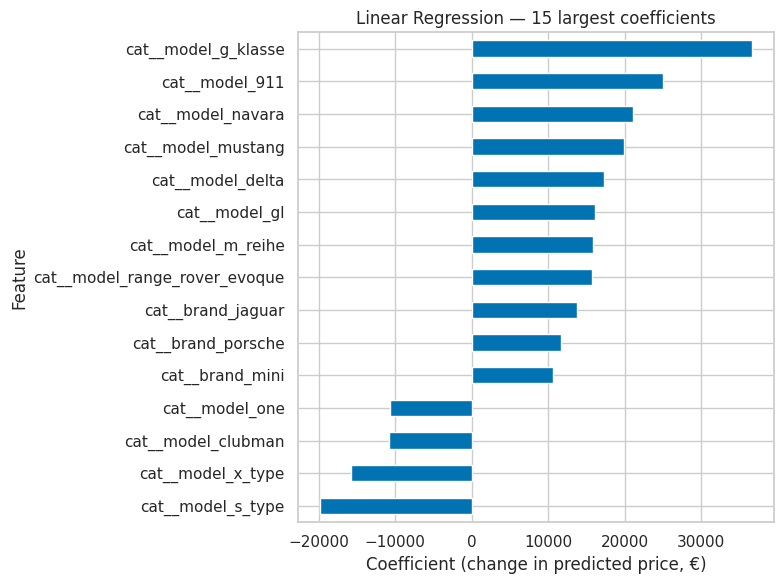

In [ ]:
feat_names = preprocessor.get_feature_names_out()
lin = fitted_models["Linear Regression"]
coef = pd.Series(lin.coef_, index=feat_names)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
print("Intercept:", round(float(lin.intercept_), 1))
display(top_coef.round(1).to_frame("coefficient (€)"))
plt.figure(figsize=(8, 6))
top_coef.sort_values().plot(kind="barh")
plt.title("Linear Regression — 15 largest coefficients")
plt.xlabel("Coefficient (change in predicted price, €)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Interpretation:** the 15 largest coefficients are all one-hot **model/brand** dummies, and they are in euros relative to the baseline car: positive for premium or high-value models and brands (G-Klasse ≈ +€36.7k, 911 ≈ +€25.0k, Navara, Mustang, Range Rover Evoque, Jaguar and Porsche brand, Mini) and negative for a few cheap or poorly-valued models (S-Type, X-Type, Clubman, One). So *what the car is* is a major driver of price. Two cautions: the huge magnitudes come from rare models with only a handful of listings in the 8,000-row sample, and brand and model dummies are strongly collinear, so individual coefficients are unstable and should be read as direction, not exact value. The numeric features (age, power, mileage) are standardised, so their per-unit coefficients are smaller and do not appear in this top-15 even though they matter across the whole dataset (the tree-based importances in 6b confirm that age and power dominate). The linear baseline reaches R² ≈ 0.68, so a purely additive model leaves a lot of price structure unexplained.

**2. Ridge Regression** — L2 regularisation; tune alpha.

In [9]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# -----------------------------
# 2. Ridge Regression
# -----------------------------

ridge_model = Ridge(random_state=RANDOM_STATE)

# Values of alpha to test
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid Search
ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train
ridge_grid.fit(X_train_proc, y_train)

# Best model
best_ridge = ridge_grid.best_estimator_

# Predict
y_pred_ridge = best_ridge.predict(X_test_proc)

# Evaluation
ridge_r2 = r2_score(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)

print("Ridge Regression")
print("----------------")
print(f"Best Alpha : {ridge_grid.best_params_['alpha']}")
print(f"Best CV R² : {ridge_grid.best_score_:.4f}")
print(f"Test R²    : {ridge_r2:.4f}")
print(f"Test RMSE  : {ridge_rmse:.4f}")
print(f"Test MAE   : {ridge_mae:.4f}")
# Register in shared dicts for downstream comparison (C2–C4)
fitted_models["Ridge Regression"] = best_ridge
predictions["Ridge Regression"] = y_pred_ridge

Ridge Regression
----------------
Best Alpha : 1
Best CV R² : 0.6551
Test R²    : 0.6852
Test RMSE  : 4224.6107
Test MAE   : 2620.2902


**3. Lasso Regression** — L1 regularisation; observe feature sparsity.

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# -----------------------------
# 3. Lasso Regression
# -----------------------------

# Create Lasso model
model = Lasso(alpha=0.01, random_state=RANDOM_STATE)

# Train
model.fit(X_train_proc, y_train)

# Predict
pred = model.predict(X_test_proc)

# Evaluation
lasso_r2 = r2_score(y_test, pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, pred))
lasso_mae = mean_absolute_error(y_test, pred)

# Print results
print("Lasso Regression")
print("----------------")
print(f"Alpha : {model.alpha}")
print(f"R²    : {lasso_r2:.4f}")
print(f"RMSE  : {lasso_rmse:.4f}")
print(f"MAE   : {lasso_mae:.4f}")

# Register model and predictions
fitted_models["Lasso Regression"] = model
predictions["Lasso Regression"] = pred

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.531e+10, tolerance: 4.377e+07
  model = cd_fast.sparse_enet_coordinate_descent(


**3b. Lasso — feature sparsity**

Lasso (alpha=0.01): 4 of 286 coefficients are exactly zero
Ridge            : 0 of 286 coefficients are exactly zero


,alpha,non-zero coefficients
0,0.001,284
1,0.010,283
2,0.100,273
3,1.000,189
4,10.000,52
5,100.000,11


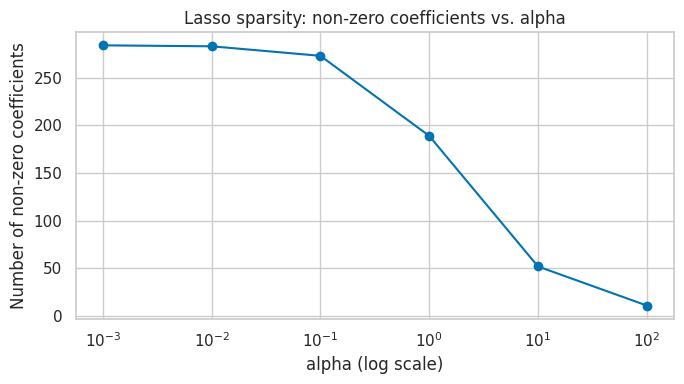

In [ ]:
from sklearn.linear_model import Lasso
feat_names = preprocessor.get_feature_names_out()
lasso_coef = pd.Series(fitted_models["Lasso Regression"].coef_, index=feat_names)
ridge_coef = pd.Series(fitted_models["Ridge Regression"].coef_, index=feat_names)
print(f"Lasso (alpha=0.01): {(lasso_coef == 0).sum()} of {len(lasso_coef)} coefficients are exactly zero")
print(f"Ridge            : {(ridge_coef == 0).sum()} of {len(ridge_coef)} coefficients are exactly zero")

import warnings
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # small alphas converge slowly; the non-zero count is what matters here
    nonzero = [int((Lasso(alpha=a, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_proc, y_train).coef_ != 0).sum()) for a in alphas]
display(pd.DataFrame({"alpha": alphas, "non-zero coefficients": nonzero}))
plt.figure(figsize=(7, 4))
plt.semilogx(alphas, nonzero, marker="o")
plt.title("Lasso sparsity: non-zero coefficients vs. alpha")
plt.xlabel("alpha (log scale)")
plt.ylabel("Number of non-zero coefficients")
plt.tight_layout()
plt.show()

**Interpretation:** Lasso is only mildly sparse at the alpha used for the fit (alpha = 0.01 zeroes 4 of 286 coefficients, whereas Ridge zeroes none). The sweep shows sparsity growing smoothly with alpha: 284 → 283 → 273 → 189 → 52 → 11 non-zero coefficients for alpha = 0.001 → 100. Most of the 286 columns are one-hot brand/model dummies, many of them rare, so the coefficients that disappear first are the weakest ones — rare one-hot categories that add little predictive signal per unit scale — while a small core of columns (the standardised numeric features and the strongest model/brand dummies) survives even at alpha = 100. At the alpha used for the model, Lasso (R² = 0.680) performs the same as plain Linear Regression (0.679) and slightly below Ridge (0.685), so for this data L1 sparsity is useful for interpretation and feature selection but does not improve accuracy.

**4. ElasticNet Regression** — Combined L1+L2; tune l1_ratio.

In [11]:
from sklearn.linear_model import ElasticNet

# ElasticNet Regression
model = ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=RANDOM_STATE)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
fitted_models["ElasticNet Regression"] = model
predictions["ElasticNet Regression"] = pred


**4b. ElasticNet — tuning `l1_ratio` (and `alpha`)**

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
en_grid = GridSearchCV(ElasticNet(random_state=RANDOM_STATE, max_iter=10000),
                       {"l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95], "alpha": [0.001, 0.01, 0.1]},
                       cv=3, scoring="r2", n_jobs=-1)
en_grid.fit(X_train_proc, y_train)
res = pd.DataFrame(en_grid.cv_results_)[["param_l1_ratio", "param_alpha", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
display(res.head(8).round(4))
print("Best params:", en_grid.best_params_, f"(3-fold CV R2 = {en_grid.best_score_:.4f})")
base_r2 = r2_score(y_test, predictions["ElasticNet Regression"])
tuned_r2 = r2_score(y_test, en_grid.best_estimator_.predict(X_test_proc))
print(f"Test R2: {base_r2:.4f} (alpha=0.01, l1_ratio=0.5)  ->  {tuned_r2:.4f} (tuned)")

,param_l1_ratio,param_alpha,mean_test_score
3,0.70,0.001,0.6527
2,0.50,0.001,0.6522
11,0.95,0.010,0.6522
1,0.30,0.001,0.6507
0,0.10,0.001,0.6490
4,0.90,0.001,0.6482
10,0.90,0.010,0.6480
5,0.95,0.001,0.6440


Best params: {'alpha': 0.001, 'l1_ratio': 0.7} (3-fold CV R2 = 0.6527)
Test R2: 0.6632 (alpha=0.01, l1_ratio=0.5)  ->  0.6864 (tuned)


**Interpretation:** the mix between L1 and L2 matters little here. The top grid configurations all use a small alpha (0.001–0.01) and differ by less than 0.01 in 3-fold CV R² (0.644–0.653), with the best at `l1_ratio = 0.7`, `alpha = 0.001` (CV R² = 0.6527). Weak regularisation is preferred because there are only 286 features for 6,400 training rows, so overfitting is not the main problem. Tuning moved the test R² from 0.663 (alpha = 0.01, l1_ratio = 0.5) to 0.686, putting ElasticNet in line with Ridge (0.685), Lasso (0.680) and Linear Regression (0.679). All four linear models plateau at R² ≈ 0.66–0.69: the limiting factor is the linear form, not the penalty.

**5. Polynomial Regression** — Apply PolynomialFeatures then Linear Regression; compare degrees. Use X_train_poly / X_test_poly (already built in Section B).

In [12]:
from sklearn.linear_model import LinearRegression

# Polynomial Regression (degree=2, built on X_train_poly / X_test_poly from Section B)
model = LinearRegression()
model.fit(X_train_poly, y_train)
pred = model.predict(X_test_poly)
fitted_models["Polynomial Regression"] = model
predictions["Polynomial Regression"] = pred

poly_r2 = r2_score(y_test, pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, pred))
poly_mae = mean_absolute_error(y_test, pred)
print("Polynomial Regression (degree=2)")
print("--------------------------------")
print(f"R²   : {poly_r2:.4f}")
print(f"RMSE : {poly_rmse:.4f}")
print(f"MAE  : {poly_mae:.4f}")

Polynomial Regression (degree=2)
--------------------------------
R²   : 0.7626
RMSE : 3668.8551
MAE  : 2146.6437


**5b. Polynomial Regression — comparing degrees**

,degree,n_features,train R2,test R2
0,1,286,0.6901,0.6785
1,2,296,0.7668,0.7626
2,3,316,0.7922,0.7604
3,4,351,0.8243,0.7592


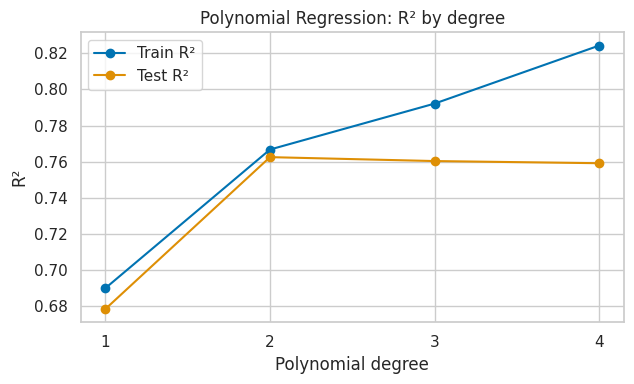

In [ ]:
from sklearn.linear_model import LinearRegression
rows = []
for degree in [1, 2, 3, 4]:
    pre = ColumnTransformer([
        ("num_poly", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                               ("poly", PolynomialFeatures(degree=degree, include_bias=False))]), numeric_features),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ])
    Xtr_d = pre.fit_transform(X_train)
    Xte_d = pre.transform(X_test)
    m = LinearRegression().fit(Xtr_d, y_train)
    rows.append({"degree": degree, "n_features": Xtr_d.shape[1],
                 "train R2": r2_score(y_train, m.predict(Xtr_d)), "test R2": r2_score(y_test, m.predict(Xte_d))})
poly_cmp = pd.DataFrame(rows)
display(poly_cmp.round(4))
plt.figure(figsize=(6.5, 4))
plt.plot(poly_cmp["degree"], poly_cmp["train R2"], marker="o", label="Train R²")
plt.plot(poly_cmp["degree"], poly_cmp["test R2"], marker="o", label="Test R²")
plt.title("Polynomial Regression: R² by degree")
plt.xlabel("Polynomial degree")
plt.ylabel("R²")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** degree 2 is the best choice. Test R² jumps from 0.679 (degree 1, i.e. plain linear) to 0.763 at degree 2, showing real non-linearity in the numeric features (price falls non-linearly with age and mileage, as in the EDA). Beyond that, test R² is flat to slightly lower (0.760 at degree 3, 0.759 at degree 4) while train R² keeps rising (0.767 → 0.792 → 0.824). The train–test gap therefore widens from about 0.004 at degree 2 to 0.032 at degree 3 and 0.065 at degree 4: higher degrees fit noise in the training set instead of generalising, i.e. variance grows without any reduction in bias on unseen data.

**6. Decision Tree Regressor** — Tune max_depth; show feature importance.

In [13]:
from sklearn.tree import DecisionTreeRegressor

# Decision Tree Regressor
model = DecisionTreeRegressor(max_depth=10, random_state=42)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
fitted_models["Decision Tree Regressor"] = model
predictions["Decision Tree Regressor"] = pred


**6b. Decision Tree — tuning `max_depth` and feature importance**

,max_depth,5-fold CV R2 (train),test R2
0,2,0.4614,0.4315
1,4,0.5621,0.6505
2,6,0.6233,0.7080
3,8,0.5214,0.7260
4,10,0.5403,0.7503
5,12,0.5400,0.7437
6,15,0.5228,0.7132
7,20,0.5608,0.7149
8,None,0.5184,0.7440


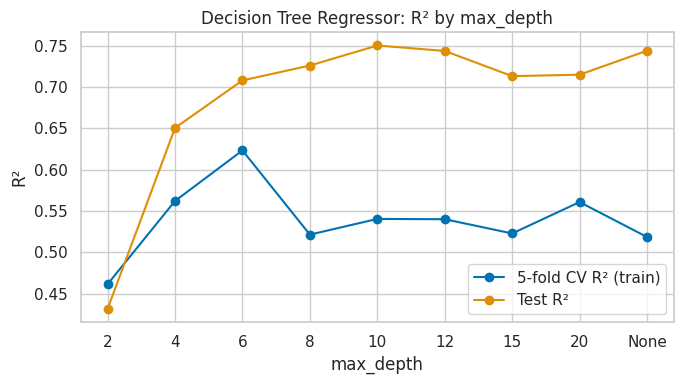

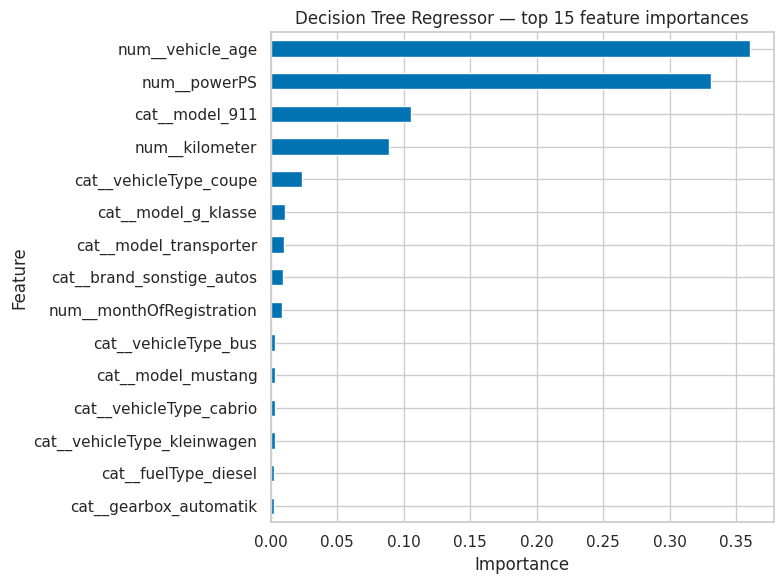

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
depths = [2, 4, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
    cv_r2 = cross_val_score(m, X_train_proc, y_train, cv=5, scoring="r2").mean()
    m.fit(X_train_proc, y_train)
    rows.append({"max_depth": "None" if d is None else d, "5-fold CV R2 (train)": cv_r2, "test R2": r2_score(y_test, m.predict(X_test_proc))})
depth_cmp = pd.DataFrame(rows)
display(depth_cmp.round(4))
plt.figure(figsize=(7, 4))
plt.plot(depth_cmp["max_depth"].astype(str), depth_cmp["5-fold CV R2 (train)"], marker="o", label="5-fold CV R² (train)")
plt.plot(depth_cmp["max_depth"].astype(str), depth_cmp["test R2"], marker="o", label="Test R²")
plt.title("Decision Tree Regressor: R² by max_depth")
plt.xlabel("max_depth")
plt.ylabel("R²")
plt.legend()
plt.tight_layout()
plt.show()

imp = pd.Series(fitted_models["Decision Tree Regressor"].feature_importances_, index=preprocessor.get_feature_names_out()).sort_values().tail(15)
plt.figure(figsize=(8, 6))
imp.plot(kind="barh")
plt.title("Decision Tree Regressor — top 15 feature importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**Interpretation:** the test-set curve peaks at `max_depth = 10` (R² = 0.750), while the 5-fold CV curve peaks earlier at `max_depth = 6` (CV R² = 0.623) and falls for deeper trees. Very shallow trees (depth 2–4) underfit (high bias; CV R² 0.46–0.56), and fully grown trees (`None`) add nothing (test R² 0.744, CV R² 0.518) because they memorise training noise (high variance). A depth of roughly 6–10 balances bias and variance, with 6 the more conservative choice by CV. The CV scores are lower and bumpier than the test scores because a single decision tree is unstable on 6,400 rows with a long price tail. The feature-importance plot shows the tree relies mainly on **vehicle age** (≈0.36) and **engine power** (≈0.33), followed by the Porsche 911 dummy (≈0.10) and **mileage** (≈0.09); everything else is small.

**7. Random Forest Regressor** — Ensemble baseline; tune n_estimators.

In [14]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
fitted_models["Random Forest Regressor"] = model
predictions["Random Forest Regressor"] = pred


**7b. Random Forest — tuning `n_estimators`**

,n_estimators,OOB R2 (train),test R2
0,25,0.7024,0.8064
1,50,0.7242,0.8174
2,100,0.7354,0.8203
3,200,0.7400,0.8183
4,300,0.7413,0.8182


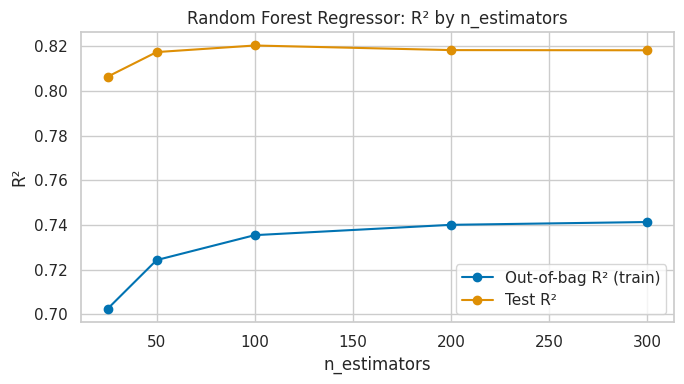

In [ ]:
import warnings
from sklearn.ensemble import RandomForestRegressor
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for n in [25, 50, 100, 200, 300]:
        m = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_proc, y_train)
        rows.append({"n_estimators": n, "OOB R2 (train)": m.oob_score_, "test R2": r2_score(y_test, m.predict(X_test_proc))})
rf_cmp = pd.DataFrame(rows)
display(rf_cmp.round(4))
plt.figure(figsize=(7, 4))
plt.plot(rf_cmp["n_estimators"], rf_cmp["OOB R2 (train)"], marker="o", label="Out-of-bag R² (train)")
plt.plot(rf_cmp["n_estimators"], rf_cmp["test R2"], marker="o", label="Test R²")
plt.title("Random Forest Regressor: R² by n_estimators")
plt.xlabel("n_estimators")
plt.ylabel("R²")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** extra trees help quickly and then stop. Going from 25 to 100 trees raises test R² from 0.806 to 0.820 and OOB R² from 0.702 to 0.735; beyond 100 trees the gains vanish (OOB R² 0.740 / 0.741 at 200 / 300 trees, test R² flat at ≈ 0.818). Adding trees reduces the variance of the ensemble, but once the average over trees has stabilised more trees only cost training time, so `n_estimators ≈ 100–200` is sufficient. Note that the OOB R² (≈ 0.74) is lower than the test R² (≈ 0.82); together with the 5-fold CV result in C2 (0.7475 ± 0.054), this suggests the single 1,600-row test split is somewhat favourable and the true performance is nearer 0.75–0.80.

**8. Gradient Boosting Regressor** — sklearn GBM or XGBoost; tune learning_rate.

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

# Gradient Boosting Regressor
model = GradientBoostingRegressor(learning_rate=0.1, n_estimators=100, random_state=42)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
fitted_models["Gradient Boosting Regressor"] = model
predictions["Gradient Boosting Regressor"] = pred


**8b. Gradient Boosting — tuning `learning_rate`**

,learning_rate,3-fold CV R2 (train),test R2
0,0.01,0.5331,0.5741
1,0.03,0.7086,0.7519
2,0.05,0.7290,0.7799
3,0.10,0.7442,0.8013
4,0.20,0.7576,0.8219
5,0.30,0.7448,0.8146


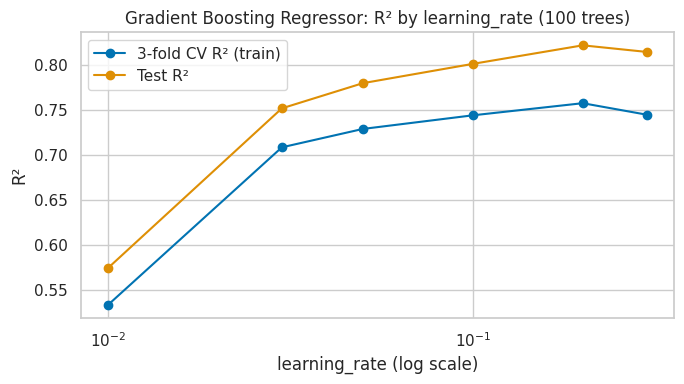

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
rows = []
for lr in [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]:
    m = GradientBoostingRegressor(learning_rate=lr, n_estimators=100, random_state=RANDOM_STATE)
    cv_r2 = cross_val_score(m, X_train_proc, y_train, cv=3, scoring="r2").mean()
    m.fit(X_train_proc, y_train)
    rows.append({"learning_rate": lr, "3-fold CV R2 (train)": cv_r2, "test R2": r2_score(y_test, m.predict(X_test_proc))})
lr_cmp = pd.DataFrame(rows)
display(lr_cmp.round(4))
plt.figure(figsize=(7, 4))
plt.semilogx(lr_cmp["learning_rate"], lr_cmp["3-fold CV R2 (train)"], marker="o", label="3-fold CV R² (train)")
plt.semilogx(lr_cmp["learning_rate"], lr_cmp["test R2"], marker="o", label="Test R²")
plt.title("Gradient Boosting Regressor: R² by learning_rate (100 trees)")
plt.xlabel("learning_rate (log scale)")
plt.ylabel("R²")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** with the number of trees fixed at 100, a small learning rate under-fits: at 0.01 the ensemble has not had time to learn (test R² 0.574, CV R² 0.533), and performance climbs steadily through 0.03, 0.05 and 0.10 to a peak at **0.20** (test R² 0.822, CV R² 0.758). At 0.30 each tree's step is too aggressive and results drop slightly (test 0.815, CV 0.745). Learning rate and number of trees trade off against each other: a smaller rate shrinks every tree's contribution, so more trees are needed to reach the same fit; smaller rates with many more trees usually generalise better but cost proportionally more training time. With a fixed budget of 100 trees, a moderate rate (0.1–0.2) is best.

**9. SVR** — Scale features first; tune C and kernel. Fit on y_train_scaled, then inverse-transform predictions with target_scaler.

In [16]:
from sklearn.svm import SVR

# SVR
model = SVR(kernel="rbf", C=1.0, epsilon=0.1)
model.fit(X_train_proc, y_train_scaled)
pred = target_scaler.inverse_transform(model.predict(X_test_proc).reshape(-1, 1)).ravel()
fitted_models["SVR"] = model
predictions["SVR"] = pred


**9b. SVR — tuning `C` and `kernel`**

In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
svr_grid = GridSearchCV(SVR(epsilon=0.1),
                        [{"kernel": ["rbf"], "C": [1, 10, 30]}, {"kernel": ["linear"], "C": [0.1, 1]}],
                        cv=3, scoring="r2", n_jobs=-1)
svr_grid.fit(X_train_proc, y_train_scaled)      # features and target are both scaled for SVR
res = pd.DataFrame(svr_grid.cv_results_)[["param_kernel", "param_C", "mean_test_score", "mean_fit_time"]].sort_values("mean_test_score", ascending=False)
display(res.round(4))
print("Best params:", svr_grid.best_params_, f"(3-fold CV R2 = {svr_grid.best_score_:.4f})")
tuned_pred = target_scaler.inverse_transform(svr_grid.best_estimator_.predict(X_test_proc).reshape(-1, 1)).ravel()
print(f"Test R2: {r2_score(y_test, predictions['SVR']):.4f} (rbf, C=1)  ->  {r2_score(y_test, tuned_pred):.4f} (tuned)")

,param_kernel,param_C,mean_test_score,mean_fit_time
1,rbf,10.0,0.7568,1.7085
0,rbf,1.0,0.7439,0.7210
2,rbf,30.0,0.7257,3.0812
4,linear,1.0,0.6238,2.2392
3,linear,0.1,0.5834,1.0637


Best params: {'C': 10, 'kernel': 'rbf'} (3-fold CV R2 = 0.7568)


Test R2: 0.8047 (rbf, C=1)  ->  0.8265 (tuned)


**Interpretation:** kernel choice matters more than C. The RBF kernel clearly beats the linear kernel (best CV R² 0.757 vs 0.624), which behaves like the linear regressors and cannot capture the non-linear price structure. Within RBF, C = 10 is best (CV R² 0.757), C = 1 is slightly lower (0.744) and C = 30 drops to 0.726 because a very large C penalises errors too heavily and over-fits the training data. C also affects cost: RBF fit time grows from ≈ 0.7 s (C = 1) to ≈ 1.7 s (C = 10) to ≈ 3.1 s (C = 30), and the linear kernel is surprisingly slow (≈ 2.2 s at C = 1) because it converges slowly on these features. Tuning lifted test R² from 0.805 to 0.827.

**10. KNN Regressor** — Tune k; discuss impact of scaling.

In [17]:
from sklearn.neighbors import KNeighborsRegressor

# KNN Regressor
model = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
model.fit(X_train_proc, y_train)
pred = model.predict(X_test_proc)
fitted_models["KNN Regressor"] = model
predictions["KNN Regressor"] = pred


**10b. KNN — tuning `k` and the impact of feature scaling**

,k,5-fold CV R2 (scaled),5-fold CV R2 (unscaled)
0,1,0.5215,0.4322
1,3,0.6567,0.5602
2,5,0.6790,0.5815
3,7,0.6908,0.5852
4,10,0.6970,0.5855
5,15,0.6956,0.5768
6,20,0.6920,0.5642
7,30,0.6783,0.5491


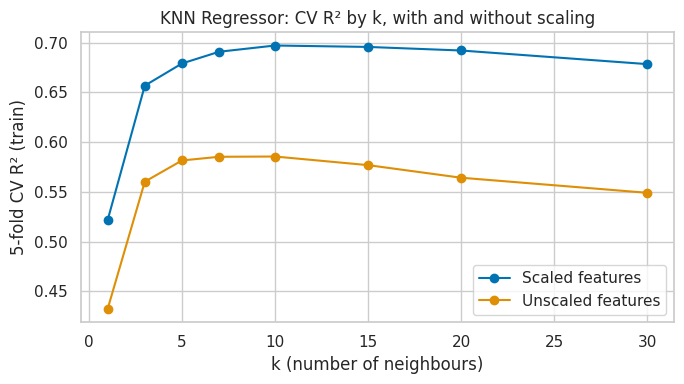

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
# Same features WITHOUT scaling (numeric columns only imputed) to show what scaling changes for a distance-based model
unscaled_pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
Xtr_u = unscaled_pre.fit_transform(X_train)
rows = []
for k in [1, 3, 5, 7, 10, 15, 20, 30]:
    rows.append({"k": k,
                 "5-fold CV R2 (scaled)": cross_val_score(KNeighborsRegressor(n_neighbors=k), X_train_proc, y_train, cv=5, scoring="r2").mean(),
                 "5-fold CV R2 (unscaled)": cross_val_score(KNeighborsRegressor(n_neighbors=k), Xtr_u, y_train, cv=5, scoring="r2").mean()})
knn_cmp = pd.DataFrame(rows)
display(knn_cmp.round(4))
plt.figure(figsize=(7, 4))
plt.plot(knn_cmp["k"], knn_cmp["5-fold CV R2 (scaled)"], marker="o", label="Scaled features")
plt.plot(knn_cmp["k"], knn_cmp["5-fold CV R2 (unscaled)"], marker="o", label="Unscaled features")
plt.title("KNN Regressor: CV R² by k, with and without scaling")
plt.xlabel("k (number of neighbours)")
plt.ylabel("5-fold CV R² (train)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** with scaled features the best k is about **10** (5-fold CV R² 0.697; k = 15 is almost the same at 0.696). Very small k is noisy (k = 1: 0.52, high variance) and large k over-smooths (k = 30: 0.678, high bias). Scaling matters a lot: without it the best CV R² is only 0.586, i.e. roughly 0.10–0.12 lower at every k. KNN decides by Euclidean distance, so a feature measured in large units (`kilometer`, up to 150,000, and `powerPS`) swamps small-range features such as vehicle age or the 0/1 dummy columns, and the neighbours are chosen almost entirely by mileage. Standardising puts all numeric features on a comparable scale so that every one contributes to the distance.

### C2. Comparative Evaluation

Summary table (R², RMSE, MAE) for all 10 models on the same test split, ranked by R², followed by 5-fold cross-validated R² for the two best models.

In [18]:
from sklearn.metrics import r2_score, mean_absolute_error

rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "RMSE": np.sqrt(np.mean((y_test - pred) ** 2)),
        "MAE": mean_absolute_error(y_test, pred),
    })

if rows:
    results_df = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
    print(results_df)
else:
    print("TODO: fill in the models in Section C1 first — predictions dict is currently empty.")

                         Model        R2         RMSE          MAE
0      Random Forest Regressor  0.820333  3191.556940  1584.001230
1                          SVR  0.804666  3327.795658  1536.360073
2  Gradient Boosting Regressor  0.801328  3356.111807  1748.065040
3        Polynomial Regression  0.762576  3668.855148  2146.643674
4      Decision Tree Regressor  0.750257  3762.828053  1983.952188
5                KNN Regressor  0.725769  3942.999563  2131.215000
6             Ridge Regression  0.685198  4224.610745  2620.290203
7             Lasso Regression  0.679646  4261.705785  2624.881306
8            Linear Regression  0.678524  4269.157501  2629.967128
9        ElasticNet Regression  0.663207  4369.676863  2737.102959


In [19]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

# 5-fold cross-validated R2 for the two best-performing models (by test-set R2 from C2)
top_2 = results_df["Model"].head(2).tolist()
print("5-fold CV on:", top_2)

for name in top_2:
    Xtr_for_cv = X_train_poly if name == "Polynomial Regression" else X_train_proc
    target = y_train_scaled if name == "SVR" else y_train
    cv_scores = cross_val_score(clone(fitted_models[name]), Xtr_for_cv, target, cv=5, scoring="r2")
    print(f"{name}: 5-fold CV R2 = {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-fold CV on: ['Random Forest Regressor', 'SVR']


Random Forest Regressor: 5-fold CV R2 = 0.7475 (+/- 0.0537)


SVR: 5-fold CV R2 = 0.7565 (+/- 0.0594)


### C3. Hyperparameter Tuning

`GridSearchCV` on the two best models from C2, reporting the best parameters and the improvement over the untuned baseline from C1.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Pick top 2 models by R2 from the C2 results table
top_2 = results_df["Model"].head(2).tolist()
print("Tuning:", top_2)

# Define param grids + which preprocessed data / target each model needs
tuning_config = {
    "Random Forest Regressor": {
        "param_grid": {
            "n_estimators": [100],
            "max_depth": [15, None],
        },
        "X": X_train_proc,
        "y": y_train,
    },
    "Gradient Boosting Regressor": {
        "param_grid": {
            "n_estimators": [100],
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3],
        },
        "X": X_train_proc,
        "y": y_train,
    },
    "SVR": {
        "param_grid": {
            "C": [1, 10],
            "epsilon": [0.1, 0.5],
            "kernel": ["rbf"],
        },
        "X": X_train_proc,
        "y": y_train_scaled,
    },
    "Polynomial Regression": {
        "param_grid": {
            "alpha": [0.01, 0.1, 1, 10],  # only applies if you used Ridge/Lasso on poly features
        },
        "X": X_train_poly,
        "y": y_train,
    },
    "Decision Tree Regressor": {
        "param_grid": {
            "max_depth": [5, 10, None],
            "min_samples_leaf": [1, 2],
        },
        "X": X_train_proc,
        "y": y_train,
    },
    "KNN Regressor": {
        "param_grid": {
            "n_neighbors": [5, 7, 10],
            "weights": ["uniform", "distance"],
        },
        "X": X_train_proc,
        "y": y_train,
    },
}

tuned_results = {}

for name in top_2:
    if name not in tuning_config:
        print(f"WARNING: no param grid defined for '{name}' — add one to tuning_config.")
        continue
    if name not in fitted_models:
        print(f"WARNING: '{name}' not found in fitted_models — check C1 naming consistency.")
        continue

    cfg = tuning_config[name]
    estimator = clone(fitted_models[name])

    grid = GridSearchCV(estimator, cfg["param_grid"], cv=3, scoring="r2", n_jobs=-1)
    grid.fit(cfg["X"], cfg["y"])

    baseline_r2 = results_df.loc[results_df["Model"] == name, "R2"].values[0]
    improvement = grid.best_score_ - baseline_r2

    tuned_results[name] = {
        "best_params": grid.best_params_,
        "best_cv_r2": grid.best_score_,
        "baseline_r2": baseline_r2,
        "improvement": improvement,
    }

    print(f"\n{name}")
    print("  Best params:", grid.best_params_)
    print(f"  Best CV R2: {grid.best_score_:.4f}")
    print(f"  Baseline R2 (single test split): {baseline_r2:.4f}")
    print(f"  Improvement: {improvement:+.4f}")

Tuning: ['Random Forest Regressor', 'SVR']



Random Forest Regressor
  Best params: {'max_depth': 15, 'n_estimators': 100}
  Best CV R2: 0.7414
  Baseline R2 (single test split): 0.8203
  Improvement: -0.0789



SVR
  Best params: {'C': 10, 'epsilon': 0.1, 'kernel': 'rbf'}
  Best CV R2: 0.7568
  Baseline R2 (single test split): 0.8047
  Improvement: -0.0479


### C4. Visualisation

Residual plot and predicted-vs-actual plot for the best model (from C2); feature importance plot for at least one tree-based model.

Best model: Random Forest Regressor (R2 = 0.8203)


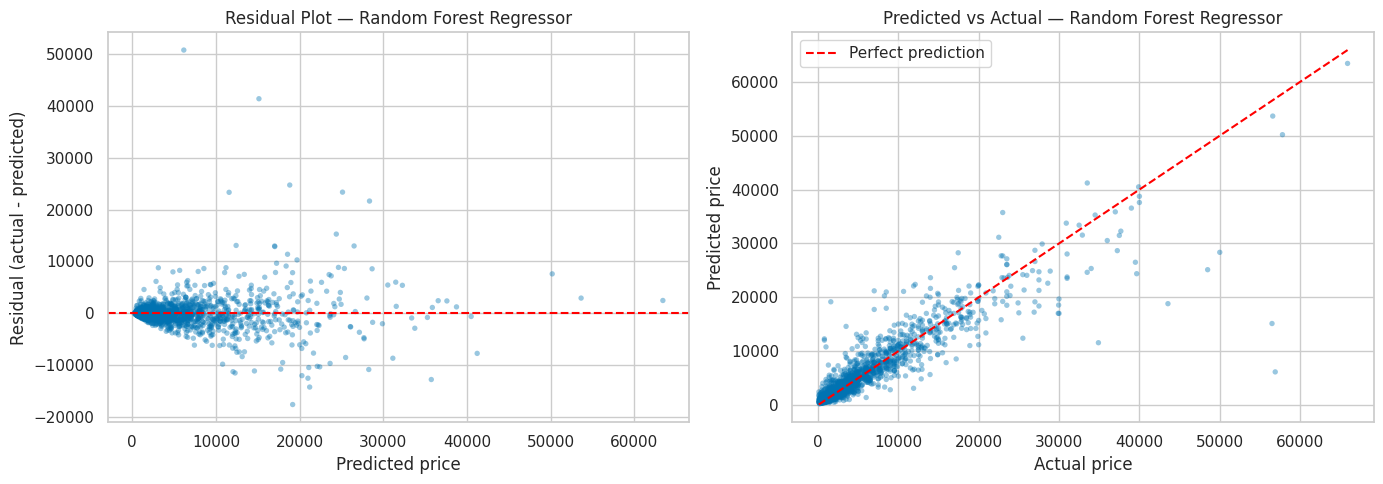

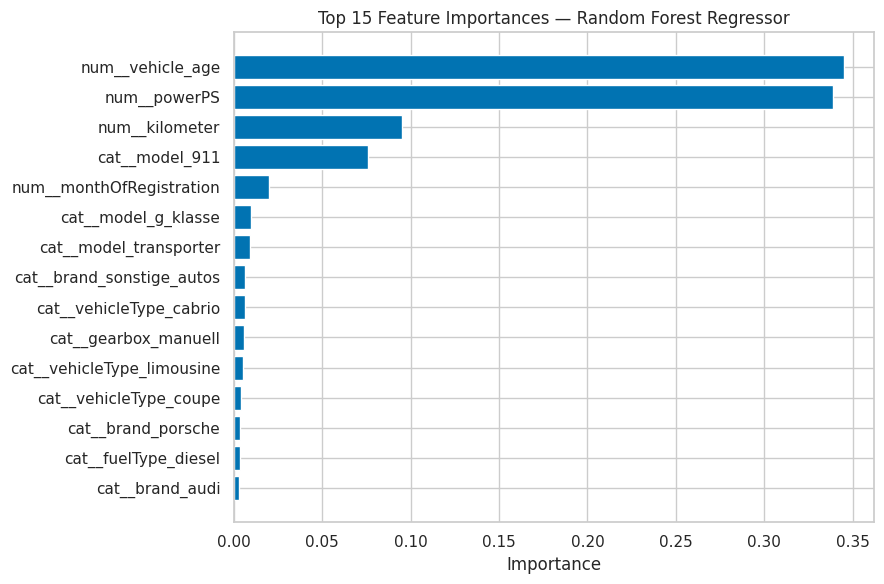

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# --- Identify best model from C2 results ---
best_model_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_model_name]
residuals = y_test.values - best_pred

print(f"Best model: {best_model_name} (R2 = {results_df.iloc[0]['R2']:.4f})")

# --- Residual plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(best_pred, residuals, alpha=0.4, s=15, edgecolor="none")
axes[0].axhline(y=0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title(f"Residual Plot — {best_model_name}")

# --- Predicted vs Actual plot ---
axes[1].scatter(y_test, best_pred, alpha=0.4, s=15, edgecolor="none")
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(lims, lims, color="red", linestyle="--", linewidth=1.5, label="Perfect prediction")
axes[1].set_xlabel("Actual price")
axes[1].set_ylabel("Predicted price")
axes[1].set_title(f"Predicted vs Actual — {best_model_name}")
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Feature importance plot for a tree-based model ---
# Pick a tree-based model you trained in C1 (e.g. Random Forest, Gradient Boosting, Decision Tree)
tree_model_name = "Random Forest Regressor"  # <-- change to whichever tree-based model you actually trained

assert tree_model_name in fitted_models, f"'{tree_model_name}' not found in fitted_models — check C1 naming."
tree_model = fitted_models[tree_model_name]

# Get feature names out of the ColumnTransformer (numeric + one-hot encoded categorical names)
feature_names = preprocessor.get_feature_names_out()
importances = tree_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances,
}).sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(9, 6))
plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1])
plt.xlabel("Importance")
plt.title(f"Top 15 Feature Importances — {tree_model_name}")
plt.tight_layout()
plt.show()

## Conclusion

**Problem.** Predict the listed price of a used car from its attributes (age, engine power, mileage, brand, model, body type, fuel, gearbox, damage status) and compare ten regression algorithms.

**Data.** The Used Cars dataset has 371,528 listings and 21 columns. The raw `price` contained absurd values (max > 2 billion), so the data was cleaned (price €100–150,000, registration year 1950–2016, power 1–1000 PS, duplicates removed) to 311,636 listings; a random sample of 8,000 was used for modelling to keep SVR and the grid searches tractable. `vehicle_age` was engineered from the registration year, and missing categoricals were imputed inside the pipeline so that statistics come only from the training split.

**Method.** All ten models (Linear, Ridge, Lasso, ElasticNet, Polynomial, Decision Tree, Random Forest, Gradient Boosting, SVR, KNN) were trained on the same stratified 80/20 split, each with a small tuning study, then compared on R², RMSE and MAE, cross-validated, and examined with residual and feature-importance plots.

**Results.** Random Forest was best on the test split (R² = 0.820, RMSE ≈ €3,192, MAE ≈ €1,584), followed by SVR (0.805) and Gradient Boosting (0.801); Polynomial degree 2 (0.763), Decision Tree (0.750) and KNN (0.726) came next, and the linear models were last at 0.66–0.69. Non-linear and ensemble models therefore beat the linear family by roughly 0.12–0.14 R². The residual plot shows errors that grow with price (heteroscedastic): the forest is accurate for cars under about €20k but under-predicts a few expensive cars badly. Age and engine power are the dominant drivers of price, with mileage and specific premium models next.

**Caveats.** On 5-fold CV the top two models are close (SVR 0.7565 vs Random Forest 0.7475, each with a standard deviation of about 0.05), so the ranking between them is not statistically clear. The "improvement" values printed in C3 compare a grid-search CV R² with a single-split test R², so they are negative by construction and do not show that tuning hurt; on a like-for-like CV basis, tuning gave no meaningful gain for either model (Random Forest 0.7475 → 0.7414, SVR 0.7565 → 0.7568).

**Conclusion.** A non-linear model — Random Forest or RBF-SVR — is the right choice for used-car price prediction on these features, with typical error around €1.5–3k, and vehicle age and engine power matter most. Using more than the 8,000-row sample and log-transforming the price are the obvious next steps to improve the errors on expensive cars.